# Same Pizza, Different Slices? — code and results

This notebook reproduces every number, table and figure in the paper *Same Pizza, Different Slices? Putting the No-Tax Assumption of Modigliani–Miller Proposition I on Trial* (Group D.E. Show&Tell, MH6806, Nanyang Technological University, 2026). Sections follow the paper.

The model lives in `model.py`. Two simulations are slow (Section 5.1, about 3 minutes; Table 3, about 2 minutes), so by default their cached results (`exp1.json`, `tcja.json`, `appC.json`) are loaded. Set `RECOMPUTE = True` to rerun everything from scratch; all random seeds are fixed. Figures are numbered as in the paper (1–3 in the main text, C1 and E1 in the appendices).

In [1]:
import json, runpy
import numpy as np, pandas as pd
from scipy.optimize import brentq
from IPython.display import Image, display
from model import *

RECOMPUTE = False
pd.set_option("display.precision", 2)
two_cf, two_p = np.array([STRONG, WEAK]), np.array([0.5, 0.5])

## 3  Results in the base model
One period, EBIT 120 or 60 with equal probability, discount rate 10%, corporate tax 20%, interest deductible, no loss carry-forward, debt at a fixed 10% rate, 20% of after-tax cash lost on default.

In [2]:
# 3.1 No-tax benchmark (promised payment 80)
VU0, Vd, Ve = 90 / 1.1, (0.5 * 80 + 0.5 * 60) / 1.1, (0.5 * 40) / 1.1
print(f"No tax:   V_U = {VU0:.1f}   debt = {Vd:.1f}   equity = {Ve:.1f}   debt + equity = {Vd + Ve:.1f}")

# 3.2 Corporate tax and the interest tax shield, Eq. (3)
VU = v_unlevered(two_cf, two_p)
g40 = gain_fixed(40, two_cf, two_p)[0]
print(f"20% tax:  V_U = {VU:.2f}   V_L(D=40) = {VU + g40:.2f}   V_L - V_U = {g40:.2f}")
print(f"PV of taxes: all-equity {0.2 * 90 / 1.1:.2f}, D = 40 {(0.5 * 23.2 + 0.5 * 11.2) / 1.1:.2f}")

# 3.3 Debt capacity, Eq. (4), and Table 1
print(f"D* = {d_star_two_state():.2f}")
table1 = pd.DataFrame([{"D": D, "weak-state after-tax cash": after_tax(WEAK, 0.1 * D), "promised repayment": 1.1 * D,
                        "weak state defaults": after_tax(WEAK, 0.1 * D) < 1.1 * D,
                        "V_L - V_U": gain_fixed(D, two_cf, two_p)[0]} for D in (40, 44, 45, 50)]).set_index("D")
table1

No tax:   V_U = 81.8   debt = 63.6   equity = 18.2   debt + equity = 81.8
20% tax:  V_U = 65.45   V_L(D=40) = 66.18   V_L - V_U = 0.73
PV of taxes: all-equity 16.36, D = 40 15.64
D* = 44.44


,weak-state after-tax cash,promised repayment,weak state defaults,V_L - V_U
D,,,,
40,48.80,44.0,False,0.73
44,48.88,48.4,False,0.80
45,48.90,49.5,True,-3.63
50,49.00,55.0,True,-3.55


## 4  Robustness
### 4.1  Parameter sensitivity (Figure 2)

In [3]:
rows = []
for tau in (0.17, 0.20, 0.30):
    Ds = d_star_two_state(tau=tau)
    rows.append({"change": f"tax rate {tau:.0%}", "D*": Ds,
                 "max gain, % of V_U": 100 * gain_fixed(Ds - 1e-9, two_cf, two_p, tau=tau)[0] / v_unlevered(two_cf, two_p, tau=tau)})
for w, s in ((70, 110), (60, 120), (50, 130)):
    cf = np.array([s, w], float); Ds = d_star_two_state(weak=w)
    rows.append({"change": f"weak / strong {w} / {s}", "D*": Ds,
                 "max gain, % of V_U": 100 * gain_fixed(Ds - 1e-9, cf, two_p)[0] / v_unlevered(cf, two_p)})
display(pd.DataFrame(rows).set_index("change"))

print("Gain just past the limit (D = 45):", {f"c={c:.0%}": round(gain_fixed(45, two_cf, two_p, c=c)[0], 2) for c in (0.05, 0.20, 0.40)})
print("Distress cost below which debt past the limit still adds value:",
      f"{brentq(lambda c: gain_fixed(44.45, two_cf, two_p, c=c)[0], 1e-3, 0.2):.1%}")
print("With c = 5% the gain turns positive again at D =", round(brentq(lambda D: gain_fixed(D, two_cf, two_p, c=0.05)[0], 50, 70), 1))

,D*,"max gain, % of V_U"
change,,
tax rate 17%,45.98,1.05
tax rate 20%,44.44,1.23
tax rate 30%,39.25,1.87
weak / strong 70 / 110,51.85,1.44
weak / strong 60 / 120,44.44,1.23
weak / strong 50 / 130,37.04,1.03


Gain just past the limit (D = 45): {'c=5%': -0.29, 'c=20%': -3.63, 'c=40%': -8.07}
Distress cost below which debt past the limit still adds value: 3.6%
With c = 5% the gain turns positive again at D = 61.5


### 4.2  Continuous cash flows (Figure 1b–c)

In [4]:
for sd in (25, 30):
    ln = lognormal_draws(sd=sd, n=200_000); lp = np.full(ln.size, 1 / ln.size)
    Ds = np.arange(0, 61, 1.0)
    g = np.array([gain_fixed(D, ln, lp)[0] for D in Ds]); k = int(g.argmax())
    print(f"sd {sd}: optimum D = {Ds[k]:.0f}, gain = {g[k]:.2f} ({100 * g[k] / v_unlevered(ln, lp):.2f}% of V_U), "
          f"P(default) = {gain_fixed(Ds[k], ln, lp)[2]:.1%}, gain first negative at D = {Ds[(g < 0) & (Ds > Ds[k])][0]:.0f}")

sd 25: optimum D = 34, gain = 0.56 (0.85% of V_U), P(default) = 1.0%, gain first negative at D = 46
sd 30: optimum D = 30, gain = 0.49 (0.74% of V_U), P(default) = 1.1%, gain first negative at D = 43


## 5  Extensions
### 5.1  Market-priced debt (Figure C1, Tables C1–C2)

In [5]:
if RECOMPUTE:
    runpy.run_path("exp1.py")
e1 = pd.DataFrame(json.load(open("exp1.json")))
e1["shareholders' gain, fixed rate"] = e1["fixed"] + e1["lender_loss"]
e1 = e1.rename(columns={"fixed": "V_L - V_U, fixed 10%", "market": "V_L - V_U, market-priced", "rate": "break-even rate",
                        "pd_fixed": "P(default), fixed", "pd_mkt": "P(default), market"}).set_index("D")
e1.loc[[20, 30, 34, 35, 40, 45, 50, 55, 60]].drop(columns="lender_loss")

,"V_L - V_U, fixed 10%","V_L - V_U, market-priced",break-even rate,"P(default), fixed","P(default), market","shareholders' gain, fixed rate"
D,,,,,,
20.0,0.36,0.36,0.10,1.50e-05,1.50e-05,0.36
30.0,0.53,0.53,0.10,2.82e-03,2.84e-03,0.55
34.0,0.56,0.57,0.10,1.01e-02,1.03e-02,0.65
35.0,0.55,0.57,0.10,1.33e-02,1.36e-02,0.68
40.0,0.43,0.51,0.11,4.11e-02,4.43e-02,0.89
45.0,0.05,0.19,0.14,9.60e-02,1.15e-01,1.31
50.0,-0.66,-0.58,0.19,1.80e-01,2.50e-01,2.06
55.0,-1.68,-2.19,0.33,2.85e-01,4.99e-01,3.29
60.0,-2.93,-3.99,0.76,4.01e-01,8.88e-01,5.06


### 5.2  Usability of the interest deduction (Figure 3a, Table C3)

In [6]:
cov = [1, 1.5, 2, 3, 3.33, 5, 10]
rows = {}
for v in (0.28, 0.6, 1.0):
    rows[f"volatility {v}"] = [100 * usable_share(k, v, n=300_000) for k in cov]
    rows[f"volatility {v} + 30% cap"] = [100 * usable_share(k, v, cap=0.30, n=300_000) for k in cov]
pd.DataFrame(rows, index=[f"coverage {k}" for k in cov]).T.round(0)

,coverage 1,coverage 1.5,coverage 2,coverage 3,coverage 3.33,coverage 5,coverage 10
volatility 0.28,89.0,98.0,99.0,100.0,100.0,100.0,100.0
volatility 0.28 + 30% cap,30.0,45.0,60.0,84.0,89.0,98.0,100.0
volatility 0.6,77.0,86.0,89.0,92.0,92.0,93.0,94.0
volatility 0.6 + 30% cap,30.0,45.0,58.0,74.0,77.0,86.0,92.0
volatility 1.0,68.0,74.0,77.0,80.0,80.0,82.0,83.0
volatility 1.0 + 30% cap,32.0,46.0,56.0,66.0,68.0,74.0,80.0


### 5.3  Personal taxes, Eq. (5) and Table 2

In [7]:
settings = [("Base model (no personal taxes)", .20, 0, 0), ("US 2017, top-bracket individual", .35, .434, .238),
            ("US from 2018, top-bracket individual", .21, .408, .238), ("US 2017, tax-exempt investor", .35, 0, 0),
            ("US from 2018, tax-exempt investor", .21, 0, 0), ("Singapore, individual investor", .17, 0, 0),
            ("S-REIT distributing its income", 0, 0, 0)]
pd.DataFrame([{"setting": n, "tau_c": a, "tau_D": b, "tau_E": c, "T*": miller_tstar(a, b, c)} for n, a, b, c in settings]).set_index("setting")

,tau_c,tau_D,tau_E,T*
setting,,,,
Base model (no personal taxes),0.20,0.00,0.00,0.20
"US 2017, top-bracket individual",0.35,0.43,0.24,0.12
"US from 2018, top-bracket individual",0.21,0.41,0.24,-0.02
"US 2017, tax-exempt investor",0.35,0.00,0.00,0.35
"US from 2018, tax-exempt investor",0.21,0.00,0.00,0.21
"Singapore, individual investor",0.17,0.00,0.00,0.17
S-REIT distributing its income,0.00,0.00,0.00,0.00


### 5.4  Multi-period debt, Eqs. (6)–(7) (Figure 3b, Table C4)

In [8]:
print("PV of the shield on D = 40 kept T years:", {T: round(float(shield_pv_maturity(40, T)), 2) for T in (1, 5, 10, 30, 10**9)})
for sd in (25, 50):
    Ds = np.arange(1, 800, 1.0)
    g = np.array([multi_period_gain(D, sd=sd)[0] for D in Ds]); j = int(g.argmax())
    gg, vu, p = multi_period_gain(Ds[j], sd=sd)
    gross = (1 - p) * TAU * 0.1 * Ds[j] / (R + p)
    print(f"EBIT volatility {sd / 90:.2f}: optimum D/V_U = {Ds[j] / vu:.0%}, coverage = {90 / (0.1 * Ds[j]):.1f}, "
          f"p = {p:.2%} a year, gain = {100 * gg / vu:.1f}% of V_U (gross shield {100 * gross / vu:.1f}%)")

PV of the shield on D = 40 kept T years: {1: 0.73, 5: 3.03, 10: 4.92, 30: 7.54, 1000000000: 8.0}
EBIT volatility 0.28: optimum D/V_U = 57%, coverage = 2.2, p = 0.33% a year, gain = 10.4% of V_U (gross shield 11.1%)
EBIT volatility 0.56: optimum D/V_U = 27%, coverage = 4.6, p = 0.38% a year, gain = 4.5% of V_U (gross shield 5.3%)


## 6  Applications
### 6.1–6.2  TCJA and Singapore in the multi-period model (Table 3)

In [9]:
if RECOMPUTE:
    runpy.run_path("tables.py")
t3 = json.load(open("tcja.json"))
pd.concat({f"EBIT volatility {int(k) / 90:.2f}": pd.DataFrame(v).set_index("label")[["cov", "D_idx", "gain", "p"]]
           for k, v in t3.items()}, axis=1).round(2)

EBIT volatility 0.28                       \
                                                  cov   D_idx   gain     p   
label                                                                        
Before TCJA: 35%, no cap                         2.09  100.00  23.38  0.52   
Rate cut only: 21%                               2.15   97.22  11.12  0.39   
Interest cap only: 35% + 30% cap                 3.08   67.75  14.38  0.15   
After TCJA: 21% + 30% cap                        2.90   71.93   7.32  0.07   
Singapore: 17%, no cap                           2.21   94.66   8.42  0.29   

                                 EBIT volatility 0.56                       
                                                  cov   D_idx   gain     p  
label                                                                       
Before TCJA: 35%, no cap                         3.96  100.00  10.90  0.83  
Rate cut only: 21%                               4.57   86.78   4.83  0.39  
Interest cap only: 35% + 30% cap                 5.88   67.40   7.47  0.45  
After TCJA: 21% + 30% cap                        5.88   67.40   3.77  0.23  
Singapore: 17%, no cap                           4.66   85.02   3.56  0.34

### 6.3  Calibration to Singapore Airlines and Sheng Siong (Table 4, Figure E1)
Operating profit, interest, debt and cash come from the companies' full-year results announcements (`firms.json`, S$ million).

In [10]:
from calib2 import table4
pd.DataFrame(table4()).T[["mu", "sd", "cv", "loss_years", "opt_cov", "opt_gain", "alt_cov", "alt_gain", "latest_cov", "min_cov"]]

,mu,sd,cv,loss_years,opt_cov,opt_gain,alt_cov,alt_gain,latest_cov,min_cov
SIA,801.3,1355.75,1.69,2,None,0.0,None,0.0,4.32,-9.38
Sheng Siong,161.13,21.75,0.13,0,1.61,11.94,2.03,8.53,35.8,35.8


## Figures (numbered as in the paper)

{'opt_D': 34.0, 'opt_gain': 0.5555000788519067, 'opt_pd': 0.010074999999999758, 'zero_D': 46.0}
Figure 1


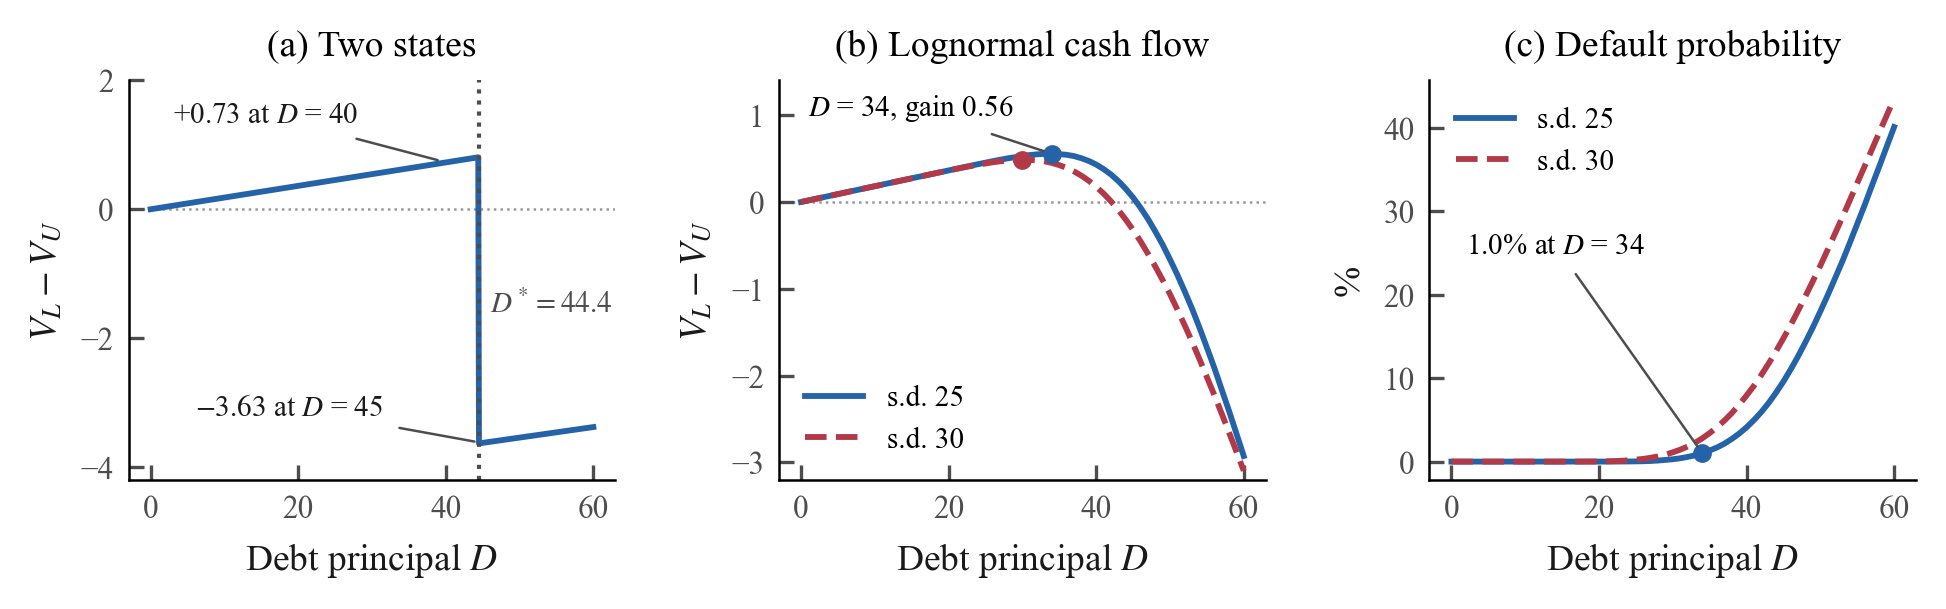

Figure 2


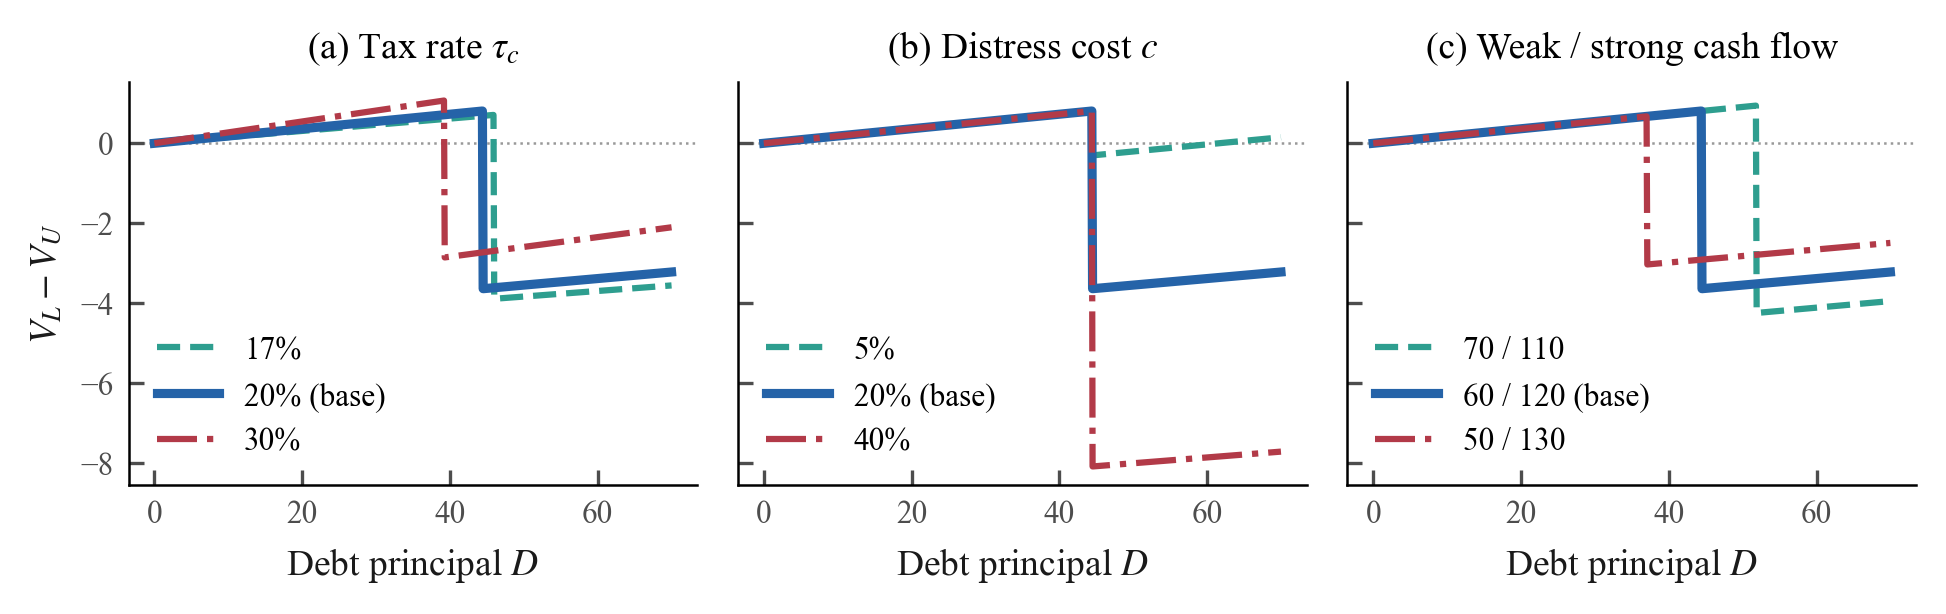

Figure 3


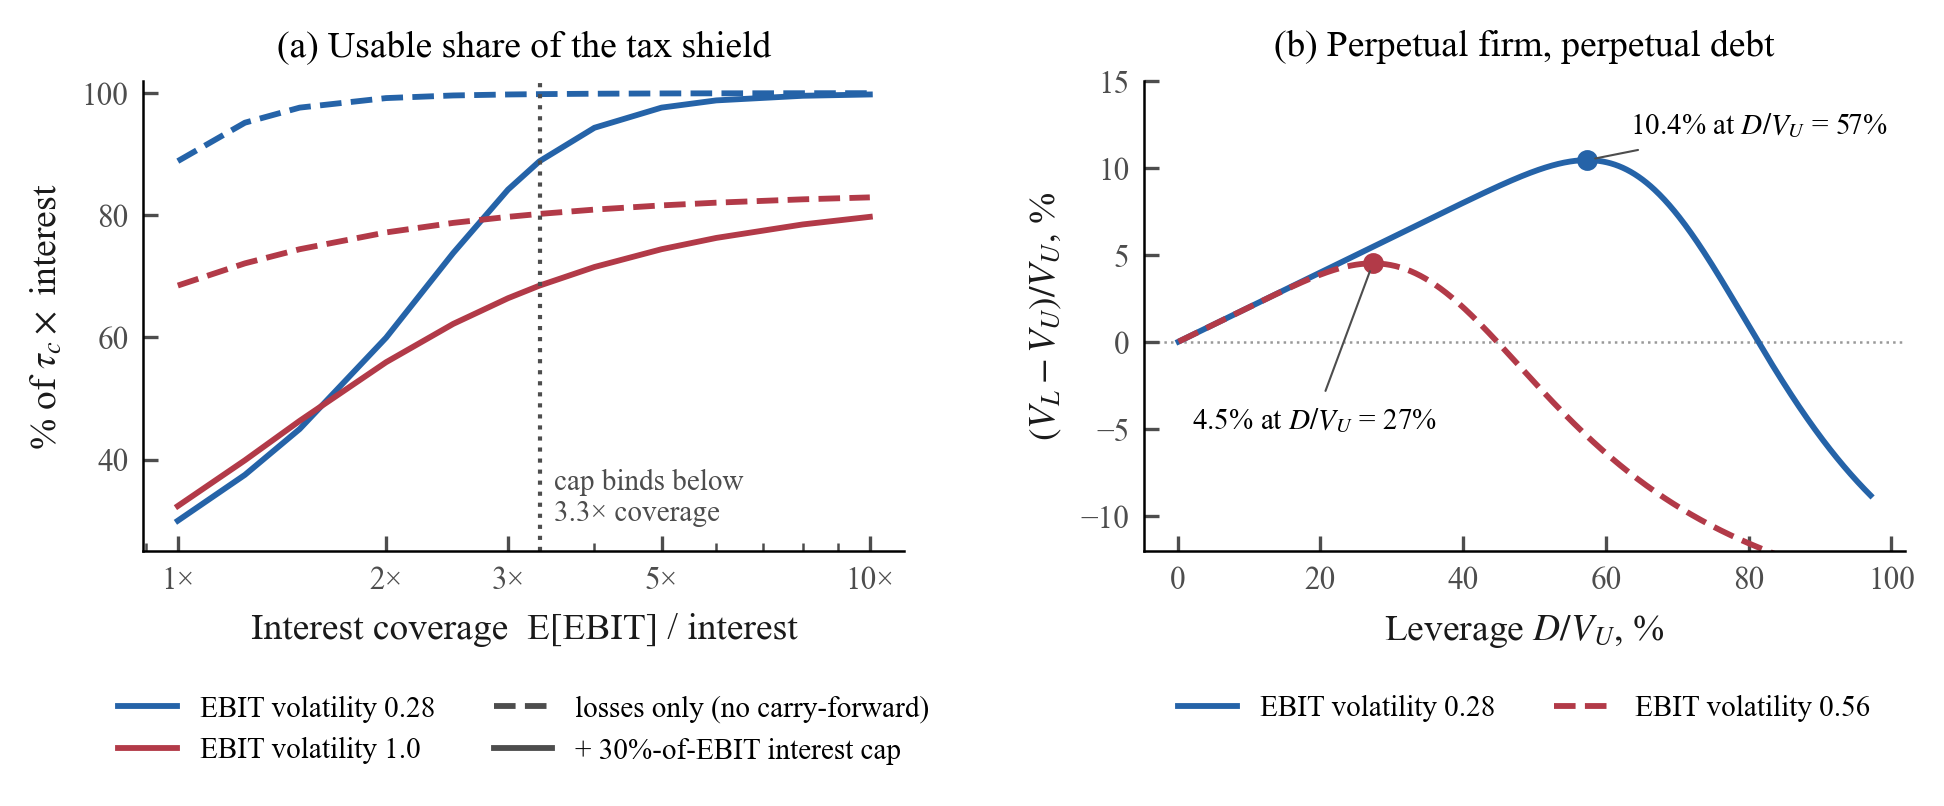

Figure C1


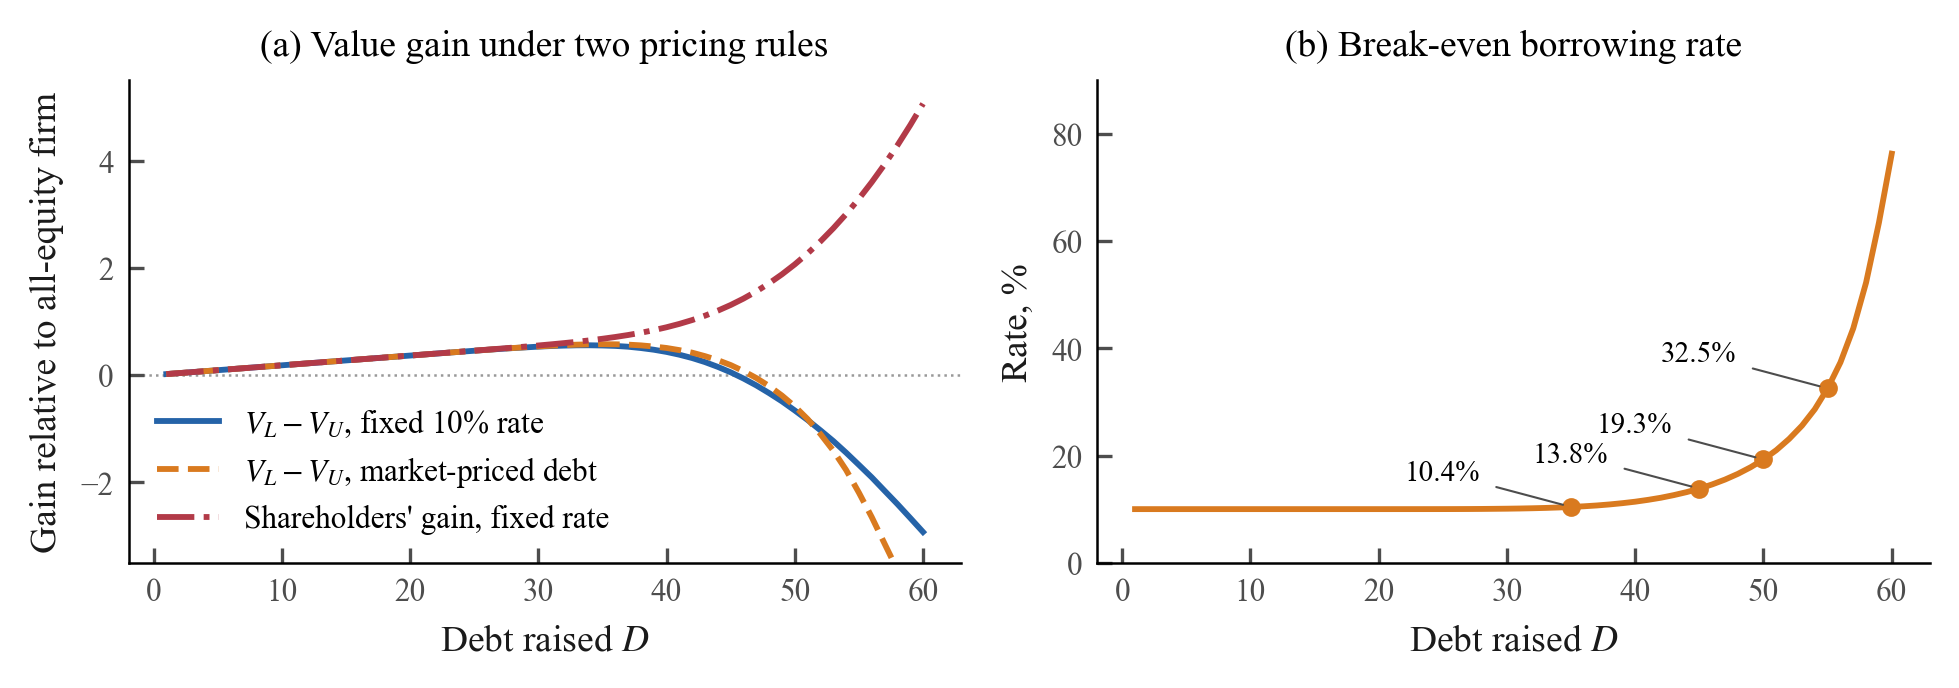

Figure E1


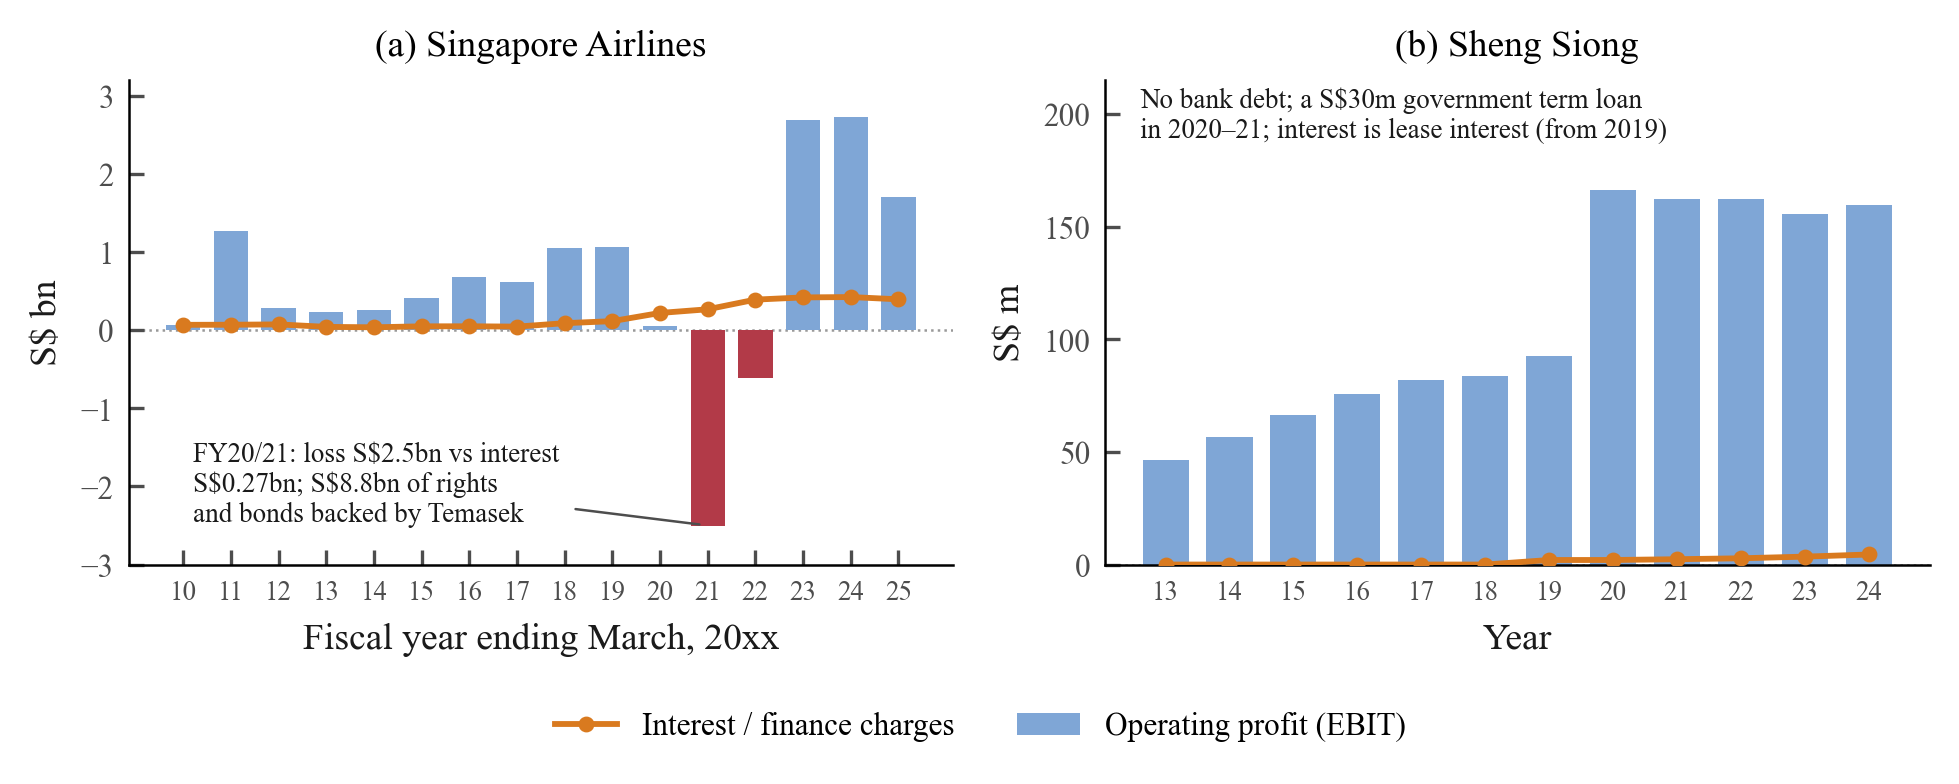

In [11]:
runpy.run_path("figs.py"); runpy.run_path("fig_firms.py")
for n, f in [("1", "fig1_value"), ("2", "fig2_sensitivity"), ("3", "fig3_shield_multiperiod"),
             ("C1", "figC1_market_debt"), ("E1", "figE1_firms")]:
    print(f"Figure {n}")
    display(Image(f"fig/{f}.png", width=900))

## Numbers quoted in the text that no table shows
`extras.py`: the money-machine trade (Section 3.3), the course toolkit at $D = 40$ (Section 3.4), distress-cost thresholds (Section 4.1), the shareholders' gain at $D = 60$ (Section 5.1), the dollar value of the gain in Section 6.1, Singapore's one-period debt limit (Section 6.2) and the calibration details of Section 6.3.

In [12]:
runpy.run_path("extras.py");

money_machine_D40 {"strong": 0.7999999999999972, "weak": 0.7999999999999972, "pv": 0.7272727272727246}
money_machine_D45 {"strong": 0.9000000000000057, "weak": -8.879999999999995, "pv": -3.6272727272727225}
toolkit_D40 {"V_U": 65.45454545454545, "V_L": 66.18181818181817, "equity_payoffs": [52.8, 4.799999999999997], "E": 26.181818181818176, "beta_E_over_beta_U": 2.5000000000000004, "hamada": 2.2222222222222223, "perpetual_shield": 8.0, "wacc": 0.08791208791208793, "V_L_from_wacc": 66.18181818181817}
var_reading_D34 {"promise": 37.400000000000006, "q01_after_tax_cash": 37.35998744867188}
lognormal_optimum_c5 {"D": 41.0, "gain": 0.6539632471298376, "p_default": 0.04972000000000455}
lognormal_optimum_c20 {"D": 34.0, "gain": 0.5555000788519067, "p_default": 0.010074999999999758}
lognormal_optimum_c40 {"D": 31.0, "gain": 0.5182906260274649, "p_default": 0.003965000000000005}
two_state {"D_star": 44.44444444444444, "gain_at_D_star": 0.8080808080626269, "c_debt_past_limit_adds_value": 0.036363

## Independent check
`independent_check.py` does not import `model.py`: it values the lognormal case by numerical integration instead of simulation.

In [13]:
runpy.run_path("independent_check.py");

two states: V_U = 65.45, D* = 44.44
Table 1: {40: 0.73, 44: 0.8, 45: -3.63, 50: -3.55}
lognormal: V_U = 65.45, optimum D = 33.8, gain = 0.557 (0.85% of V_U), P(default) = 0.92%, gain back to zero at D = 45.5
